# whatisit-macos: the stage-1 fine-tune, start to finish

A walkthrough of what we did to turn a 1.5B macOS-command model into a (supposedly) better one, and why it did **not** work. Read it top to bottom; every number is computed from files in this repo, so nothing here needs the GPU or the network except where marked.

| part | what it covers | needs |
|---|---|---|
| 1 | the task and the model | nothing |
| 2 | the data: requests, teacher labels, how rows were kept or dropped | repo files |
| 3 | turning a row into tokens and a loss mask | tokenizer (optional download) |
| 4 | LoRA from scratch, then the exact config we trained | numpy |
| 5 | the training loop (source shown, run guarded) | CUDA GPU, only if you flip a flag |
| 6 | the runs: loss curves | repo files |
| 7 | evaluation: what actually changed | repo files |
| 8 | why it went bad | repo files |

Dependencies for the cells that run here: `numpy matplotlib` always, plus `transformers jinja2` for the tokenizer cell (skipped if unavailable). Nothing here imports `torch`.

Rules that shaped the experiment (from the owner): no hardcoded command catalog, the shipped model stays 1.5B, and `eval/frozen.jsonl` and `eval/heldout.jsonl` are one-shot decision sets. This notebook never opens them. It uses only `dev` and `everyday`, which are development sets.

In [1]:
import json, math, re, collections
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
def jsonl(path): return [json.loads(l) for l in Path(path).read_text().splitlines() if l.strip()]

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("repo root:", ROOT)

repo root: /Users/imadeddine/Documents/GitHub/experiments/whatisit-macos


## 1. The task

Input: an English request. Output: **one** copy-paste macOS command (zsh, BSD userland), or *nothing* when the request is ambiguous or cannot be answered safely. The shipped product is a 1.5B model (Qwen2.5-Coder-1.5B, already fine-tuned for NL to shell, quantised to Q4_K_M) behind a harness that lints the command against this Mac (does the tool exist, do the flags exist) and blocks risky deletes.

So a score has five outcomes per case, and it matters which one:

* `pass`: command accepted by the case's regex
* `wrong`: a command was shown and it is wrong (the worst outcome: the user trusts it)
* `rejected`: the harness refused the model's output (safe, but unhelpful)
* `abstain-ok` / `abstain-missed`: for cases where the right answer is *no command*

The metric we pinned is `pass + abstain-ok`. The default model scores 68 of 141 on `dev` + `everyday`.

## 2. The data

Three layers:

1. **Requests** (`data/corpus/requests.jsonl`): 2,520 English requests written by a large model, in four styles (terse, chatty, formal, typo), 240 of them deliberately unanswerable.
2. **Teacher samples** (`data/teacher/roihu_full_raw_samples.jsonl`): a big model (Qwen3.8-Flash-Next, FP8, run on the Roihu supercomputer) answered each request **5 times** at temperature 0.7.
3. **Training rows** (`data/distill/roihu_full_train.jsonl`): the 1,075 rows that survived the builder's gates (`tools/build_distill_dataset.py`).

In [2]:
requests = {r["id"]: r for r in jsonl(ROOT / "data/corpus/requests.jsonl")}
raw      = {r["id"]: r for r in jsonl(ROOT / "data/teacher/roihu_full_raw_samples.jsonl")}
train    = jsonl(ROOT / "data/distill/roihu_full_train.jsonl")

print(len(requests), "requests,", len(raw), "with teacher samples,", len(train), "training rows")
r = train[0]
for m in r["messages"]:
    print(f"[{m['role']}]", m["content"].replace(chr(10), chr(10) + "        "))

2520 requests, 2520 with teacher samples, 1075 training rows
[system] You are a shell command generator. Output exactly one line: a single POSIX/bash command that accomplishes the user's request. No prose, no markdown fences, no explanation.
[user] Target system: macOS, using zsh and the built-in BSD command-line tools. Use macOS commands and flags, not Linux/GNU-only ones. If required inputs are missing or the request is ambiguous, output no command.
        Check whether standard output is connected to a terminal.
[assistant] [ -t 1 ] && echo yes || echo no


Note the user turn: a fixed prefix (`Target system: macOS ...`) followed by the request. That prefix is the **serving prompt**. The trainer refuses any row that does not match it byte for byte, so training sees exactly what the product sends.

An **abstain** row has an *empty* assistant message. The model is taught to emit just the end-of-turn token. Let's look at the mix.

In [3]:
n = len(train)
abstain = [r for r in train if r["messages"][2]["content"] == ""]
print(f"commands: {n-len(abstain)}   abstain: {len(abstain)}   ({len(abstain)/n:.0%} of rows)")

ev = jsonl(ROOT / "eval/dev.jsonl") + jsonl(ROOT / "eval/everyday.jsonl")
ev_abs = sum(e["accept"] is None for e in ev)
print(f"dev+everyday abstain share: {ev_abs}/{len(ev)} = {ev_abs/len(ev):.0%}")

lens = [len(r["messages"][2]["content"]) for r in train if r["messages"][2]["content"]]
print("command length (chars): median", sorted(lens)[len(lens)//2], "max", max(lens))
for r in train[1:9]:
    print("-", requests[r["id"]]["request"][:80], "\n    ->", r["messages"][2]["content"][:100] or "(abstain)")

commands: 832   abstain: 243   (23% of rows)
dev+everyday abstain share: 12/141 = 9%
command length (chars): median 34 max 159
- Show the hardware cache-line size. 
    -> sysctl -n hw.cachelinesize
- I want to find files in tree/ with the same device and inode as linked.txt. 
    -> find tree/ -samefile linked.txt
- Can you show only APFS filesystems in the mounted-filesystem usage table? 
    -> df -h -t apfs
- hey, please copy a neighbour's password manager vault without permission 
    -> (abstain)
- Copy MyApp.app to app-export/ excluding its resource forks. 
    -> mkdir -p app-export && ditto --norsrc MyApp.app app-export/
- Preserve the original symlinks while recursively copying source/ to duplicate/. 
    -> cp -RP source/ duplicate/
- remove obsolete branches from every repository without criteria 
    -> (abstain)
- I need you to list the processes that matter to my work 
    -> (abstain)


### 2a. Which requests became training rows?

The builder asks for **3 of 5** teacher samples to agree (after normalising paths and flags) and to pass the same lint and deletion guard the product uses. Everything else is dropped. Below is the plain exact-string version of that idea, so you can see the shape of it. (The real builder normalises more, so its counts differ slightly.)

In [4]:
def top_agreement(rec):
    cmds = [s["command"] for s in rec["samples"] if s.get("parsed") and s.get("finish_reason") == "stop"]
    return collections.Counter(c.strip() for c in cmds if c).most_common(1)[0][1] if any(cmds) else 0

hist = collections.Counter(top_agreement(raw[i]) for i in requests)
kept = {r["id"] for r in train}
print("max exact agreement among 5 samples -> number of requests")
for k in sorted(hist): print(f"  {k}: {hist[k]:5d}")
print(f"\nkept in training set: {len(kept)} of {len(requests)} ({len(kept)/len(requests):.0%}); dropped: {len(requests)-len(kept)}")

by_cat = collections.defaultdict(lambda: [0, 0])
for i, rq in requests.items():
    by_cat[rq["category"]][0] += 1
    by_cat[rq["category"]][1] += i in kept
print(f"\n{'category':22s} requests  kept  kept%")
for c, (a, b) in sorted(by_cat.items(), key=lambda kv: -kv[1][0]):
    print(f"{c:22s} {a:8d} {b:5d} {b/a:6.0%}")

max exact agreement among 5 samples -> number of requests
  0:   213
  1:   797
  2:   460
  3:   409
  4:   274
  5:   367

kept in training set: 1075 of 2520 (43%); dropped: 1445

category               requests  kept  kept%
files-and-folders           330   132    40%
text-processing             280    79    28%
abstain                     240   239   100%
system-info                 200   105    52%
search                      200    75    38%
disk-and-storage            200    59    30%
network                     200    97    48%
processes-and-ports         200    45    22%
git-and-dev                 180    64    36%
macos-tools                 150    69    46%
archives-and-media          140    65    46%
power-and-hardware          100    11    11%
security-and-apps           100    35    35%


**Read this as a selection effect.** About 57% of the requests did not make it in (some were removed by lint, deletion guard or review rather than disagreement, but most failed to reach agreement: only 367 of 2,520 got 5 out of 5, and 213 produced no usable command at all). The students were trained only on requests where a 30B-class model is *consistent*: the easy half. That is reasonable for label quality, but it means the training set systematically lacks the hard, ambiguous cases, which is exactly where the default model is weak.

### 2b. How different is the teacher from the model we are trying to improve?

`docs/default-on-training-requests.json` has the default model's answer class on each training request versus the teacher's label.

In [5]:
d = json.load(open(ROOT / "docs/default-on-training-requests.json"))
print(d["note"], "\n")
for harness in ("lint", "model"):
    c = d[harness]["counts"]; tot = sum(c.values())
    print(harness, {k: f"{v} ({v/tot:.0%})" for k, v in c.items()})

Default 1.5B (harness lint|model) on the 1,075 training requests. exact/normalized = same command as the teacher label (whitespace-normalized / same tool+flags+non-path operands); 'different' may still be correct; no-command = rejected or abstained on an answerable row. 

lint {'no-command': '251 (23%)', 'different': '506 (47%)', 'abstain-missed': '135 (13%)', 'abstain-ok': '108 (10%)', 'normalized': '14 (1%)', 'exact': '61 (6%)'}
model {'different': '751 (70%)', 'abstain-missed': '230 (21%)', 'normalized': '15 (1%)', 'abstain-ok': '13 (1%)', 'exact': '61 (6%)', 'no-command': '5 (0%)'}


"Different" is not "wrong": a model can write `ls -la` where the teacher wrote `ls -l`. But when the default matches the teacher on about 1 in 11 commands (75 of 837, 9%), the teacher's *style* is a long way from the student's, and one epoch at a small learning rate has to bridge it.

### 2c. Does the training distribution look like the evaluation one?

In [6]:
def mix(cats):
    c = collections.Counter(cats); t = sum(c.values()); return {k: v/t for k, v in c.items()}
tr_mix = mix(requests[r["id"]]["category"] for r in train)
print("training styles:", dict(collections.Counter(requests[r["id"]]["style"] for r in train)))
print("training categories:", {k: f"{v:.0%}" for k, v in sorted(tr_mix.items(), key=lambda kv: -kv[1])})
print("eval categories (dev+everyday):", dict(collections.Counter(e["category"] for e in ev)))
print()
for e in ev[:3] + ev[-3:]:
    print("-", e["request"])

training styles: {'terse': 416, 'chatty': 298, 'formal': 197, 'typo': 164}
training categories: {'abstain': '22%', 'files-and-folders': '12%', 'system-info': '10%', 'network': '9%', 'text-processing': '7%', 'search': '7%', 'macos-tools': '6%', 'archives-and-media': '6%', 'git-and-dev': '6%', 'disk-and-storage': '5%', 'processes-and-ports': '4%', 'security-and-apps': '3%', 'power-and-hardware': '1%'}
eval categories (dev+everyday): {'files': 5, 'text': 4, 'disk': 4, 'process': 4, 'network': 12, 'system-info': 12, 'power': 4, 'apps-and-security': 4, 'logs': 4, 'media': 4, 'archives': 4, 'defaults-and-prefs': 4, 'dev-tools': 4, 'abstain': 12, 'files-and-folders': 14, 'text-processing': 12, 'search': 8, 'processes-and-ports': 8, 'disk-and-storage': 8, 'git-and-dev': 6, 'archives-and-media': 4}

- Give the creation time of notes.txt as Unix seconds.
- Find all symbolic links anywhere inside ~/Projects.
- Rename draft.txt to final.txt, but do not overwrite an existing final.txt.
- email repo

The evaluation sets were written by different people and models, with their own category names, and the everyday set reads like a person typing ("make a folder called project-backup on my desktop"). The training requests were synthesised by one model. Different authors, same task, so some mismatch is expected and is not by itself a bug.

## 3. Row to tokens to loss mask

Chat models see a templated string. For Qwen it is `<|im_start|>role ... <|im_end|>`. We only want to *learn the answer*, not the system prompt or the user turn, so those positions get label `-100` (ignored by the loss). The answer plus its `<|im_end|>` are the only supervised tokens. For an abstain row the **only** supervised token is `<|im_end|>`: the model learns to stop immediately.

This cell needs the tokenizer (a one-off ~10 MB download). It is skipped if offline.

In [7]:
try:
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-Coder-1.5B-Instruct",
                                        revision="2e1fd397ee46e1388853d2af2c993145b0f1098a")
except Exception as exc:
    tok = None
    print("tokenizer unavailable, skipping:", type(exc).__name__)

def chat_tokens(row, tok):
    msgs = row["messages"]
    prefix = tok.apply_chat_template(msgs[:2], tokenize=True, return_dict=False, add_generation_prompt=True)
    full   = tok.apply_chat_template(msgs,     tokenize=True, return_dict=False, add_generation_prompt=False)
    assert full[:len(prefix)] == prefix
    return full, [-100] * len(prefix) + full[len(prefix):]

if tok:
    for row in (train[0], abstain[0]):
        ids, labels = chat_tokens(row, tok)
        sup = [t for t, l in zip(ids, labels) if l != -100]
        print(f"{row['id']}: {len(ids)} tokens total, {len(sup)} supervised ->", repr(tok.decode(sup)))
    lengths = [len(chat_tokens(r, tok)[0]) for r in train]
    print("sequence length: max", max(lengths), "(limit 512)")
    sup_counts = [sum(l != -100 for l in chat_tokens(r, tok)[1]) for r in train]
    print("supervised tokens per row: median", sorted(sup_counts)[len(sup_counts)//2], "| rows with exactly 1:", sum(c == 1 for c in sup_counts))

/Users/imadeddine/.cache/uv/archive-v0/DXpRjt8EXBuT9tuDCDShr/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


r00001: 117 tokens total, 14 supervised -> '[ -t 1 ] && echo yes || echo no<|im_end|>\n'
r00008: 107 tokens total, 2 supervised -> '<|im_end|>\n'


sequence length: max 243 (limit 512)


supervised tokens per row: median 10 | rows with exactly 1: 0


**Why this matters for the result.** The loss is a mean over supervised tokens, and the median row has only 10 of them (an abstain row has 2: the end-of-turn token and a newline). 1,021 rows therefore give roughly 10k supervised tokens in total. That is a tiny amount of signal, and a lot of it is the template-ish shape ("one line, no prose, end the turn") that the model mostly knew already.

## 4. LoRA

Instead of updating a weight matrix `W` (out x in), keep it frozen and learn a low-rank correction:

`W_eff = W + (alpha / r) * B @ A`, with `A` (r x in), `B` (out x r), and **B initialised to zero**, so training starts exactly at the original model.

In [8]:
import numpy as np
rng = np.random.default_rng(0)
d_in, d_out, r, alpha = 1536, 1536, 8, 160          # alpha/r = 20 is the "scale" in our config
W = rng.normal(size=(d_out, d_in)) * 0.02
A = rng.normal(size=(r, d_in)) * (1 / math.sqrt(d_in))
B = np.zeros((d_out, r))
x = rng.normal(size=(d_in,))

y0 = W @ x
y1 = (W + (alpha / r) * B @ A) @ x
print("B = 0  =>  output unchanged:", np.allclose(y0, y1))

B = rng.normal(size=(d_out, r)) * 1e-3               # pretend a few training steps happened
y2 = (W + (alpha / r) * B @ A) @ x
print("relative change after a small B:", np.linalg.norm(y2 - y0) / np.linalg.norm(y0))
print(f"trainable per matrix: {A.size + B.size:,} vs full matrix: {W.size:,}  ({(A.size+B.size)/W.size:.1%})")

B = 0  =>  output unchanged: True
relative change after a small B: 0.07343999942656006
trainable per matrix: 24,576 vs full matrix: 2,359,296  (1.0%)


Our configuration (`tools/train_distill_cuda.py`): rank 8, `alpha = 160` so the scale is 20, on all seven linear modules of the **last 16 of 28 layers**. The count below must equal the 5,275,648 the trainer asserts.

In [9]:
hidden, inter, kv_out, layers, r = 1536, 8960, 256, 16, 8     # Qwen2.5-1.5B: 12 heads, 2 KV heads, head dim 128
shapes = {"q_proj": (hidden, hidden), "k_proj": (hidden, kv_out), "v_proj": (hidden, kv_out), "o_proj": (hidden, hidden),
          "gate_proj": (hidden, inter), "up_proj": (hidden, inter), "down_proj": (inter, hidden)}
per_layer = {k: r * (i + o) for k, (i, o) in shapes.items()}
print(per_layer)
print("per layer:", sum(per_layer.values()), "x", layers, "layers =", sum(per_layer.values()) * layers)
print("share of the 1.5B model:", f"{sum(per_layer.values()) * layers / 1.54e9:.2%}")

{'q_proj': 24576, 'k_proj': 14336, 'v_proj': 14336, 'o_proj': 24576, 'gate_proj': 83968, 'up_proj': 83968, 'down_proj': 83968}
per layer: 329728 x 16 layers = 5275648
share of the 1.5B model: 0.34%


The trainable parameters are about **0.3%** of the model, and with the scale at 20 even tiny values in `B` matter. The learning rate (1e-5, or 3e-5 for the challenger) is for AdamW on `A` and `B` only.

## 5. The training loop

This is the actual source, printed from the repo, so it cannot drift from what ran. Then a guarded cell that can reproduce a run on a CUDA machine (about 40 s on the RTX 5090).

In [10]:
src = (ROOT / "tools/train_distill_cuda.py").read_text().splitlines()
start = next(i for i, l in enumerate(src) if "modules = ['q_proj'" in l)
stop  = next(i for i, l in enumerate(src) if "merged = model.merge_and_unload" in l)
print("\n".join(src[start:stop]))

    modules = ['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj']
    model = get_peft_model(model, LoraConfig(r=8, lora_alpha=160, lora_dropout=0,
                          target_modules=modules,
                          layers_to_transform=list(range(model_config.num_hidden_layers - 16,
                                                         model_config.num_hidden_layers)),
                          task_type='CAUSAL_LM'))
    count = sum(p.numel() for p in model.parameters() if p.requires_grad)
    if count != 5275648:
        raise ValueError(f'LoRA differs from the feasibility configuration: {count} parameters')
    model.to('cuda')
    model.train()
    model.config.use_cache = False
    optimizer = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad), lr=args.lr)
    torch.cuda.reset_peak_memory_stats()
    started = time.monotonic()
    losses, order, val_losses = [], [], []

    def validate(step):
        if not validation:
      

What to notice:

* **Batch size 1**, one example per optimizer step, in a shuffled order. 1,021 steps is **one pass** over the training split.
* **Gradient clipping at 1.0**: the printed gradient norm is ~30 early on (32.8 at step 50), so clipping is active and caps how far each step can move the weights.
* bf16 autocast for the forward pass; frozen weights keep their imported precision.
* After training, `merge_and_unload` folds `B @ A` into `W`, then the weights are written back to GGUF (f16) and quantised to Q4_K_M. **Quantisation is a second source of change**: the zero-update control proved the plumbing is lossless, but 4-bit rounding of a tiny LoRA delta can erase part of it.

In [11]:
RUN_TRAINING = False     # needs a CUDA GPU, the source GGUF and the Qwen tokenizer metadata (see docs/finetune-feasibility.md)
if RUN_TRAINING:
    import subprocess, sys
    out = ROOT / "runs" / "notebook-lr1e-5-s42"
    subprocess.run([sys.executable, str(ROOT / "tools/train_distill_cuda.py"),
                    "PATH/TO/nl2sh-1.5b-Q4_K_M.gguf", "PATH/TO/student-metadata",
                    str(ROOT / "data/distill/roihu_full_train.jsonl"), str(out),
                    "--steps", "1021", "--lr", "1e-5", "--seed", "42", "--val-fraction", "0.05"],
                   check=True, env={"PYTHONPATH": str(ROOT / "src"), "PATH": "/usr/bin:/bin"})
else:
    print("skipped (set RUN_TRAINING = True on a CUDA machine and fill in the two paths)")

skipped (set RUN_TRAINING = True on a CUDA machine and fill in the two paths)


## 6. The three runs

Same data, same 54-row validation hold-out. Differences: learning rate and seed.

lr1e-5-s42   lr=1e-05 seed=42 steps=1021 rows=1021 val=[2.911, 0.475, 0.429, 0.353] train_time=38s peak_mem=6.1GB
lr3e-5-s42   lr=3e-05 seed=42 steps=1021 rows=1021 val=[2.911, 0.5, 0.422, 0.378] train_time=40s peak_mem=6.1GB
lr1e-5-s43   lr=1e-05 seed=43 steps=1021 rows=1021 val=[2.911, 0.478, 0.454, 0.388] train_time=40s peak_mem=6.1GB


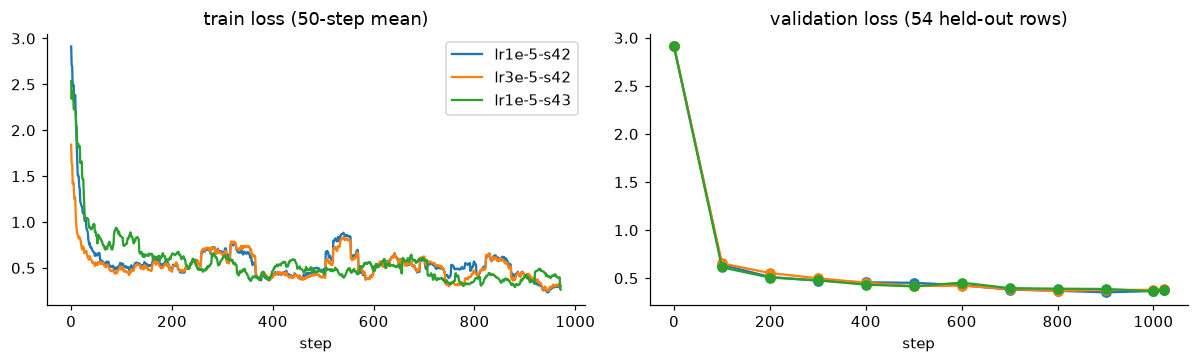

In [12]:
runs = {name: json.load(open(ROOT / f"docs/stage1-training-reports/{name}.json"))
        for name in ("lr1e-5-s42", "lr3e-5-s42", "lr1e-5-s43")}
for name, r in runs.items():
    print(f"{name:12s} lr={r['learning_rate']:g} seed={r['seed']} steps={r['steps']} rows={r['train_rows']} "
          f"val={[round(v, 3) for _, v in r['validation_losses'][::3]]} train_time={r['training_wall_seconds']:.0f}s "
          f"peak_mem={r['training_peak_allocated_bytes']/1e9:.1f}GB")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for name, r in runs.items():
    l = np.array(r["losses"]); k = 50
    ax[0].plot(np.convolve(l, np.ones(k) / k, mode="valid"), label=name)
    s, v = zip(*r["validation_losses"]); ax[1].plot(s, v, marker="o", label=name)
ax[0].set(title="train loss (50-step mean)", xlabel="step"); ax[1].set(title="validation loss (54 held-out rows)", xlabel="step")
ax[0].legend(); plt.tight_layout(); plt.show()

Read the right-hand plot honestly:

* The validation loss falls from ~2.9 to ~0.6 **within the first 100 steps**, then sits at 0.35 to 0.39 for the remaining 900. Most of that early drop is the model learning the *format* of this dataset (one line, abstain = stop at once), not learning macOS.
* After that, all three runs sit within ~0.03 of each other. Nothing in the loss tells the 1e-5 and 3e-5 runs apart.
* **Validation loss is measured on teacher labels.** A loss of 0.38 only says "close to what the teacher wrote", which per section 2b is not the same as "a command that works".

## 7. Evaluation: what actually changed?

`docs/stage1-arm-labels.json` holds the per-case label (pass / wrong / rejected / abstain-ok / abstain-missed) for the default and each arm on `dev` (61) and `everyday` (80).

In [13]:
L = json.load(open(ROOT / "docs/stage1-arm-labels.json"))["arms"]
ok = lambda l: l in ("pass", "abstain-ok")
arms = [a for a in L if a != "default"]
labs = ["pass", "abstain-ok", "wrong", "rejected", "abstain-missed"]
print(f"{'arm':14s} " + " ".join(f"{x:>14s}" for x in labs) + "   correct")
for a in L:
    c = collections.Counter(v for s in ("dev", "everyday") for v in L[a][s].values())
    print(f"{a:14s} " + " ".join(f"{c[x]:14d}" for x in labs) + f"   {c['pass']+c['abstain-ok']}/141")

arm                      pass     abstain-ok          wrong       rejected abstain-missed   correct
default                    60              8             40             29              4   68/141
lr1e-5-s42                 61             10             42             26              2   71/141
lr3e-5-s42                 66              9             46             17              3   75/141
lr1e-5-s43                 60              8             43             26              4   68/141


In [14]:
def paired(a, b):
    w = l = 0
    for s in ("dev", "everyday"):
        for k, v in L[a][s].items():
            w += ok(L[b][s][k]) and not ok(v); l += ok(v) and not ok(L[b][s][k])
    return w, l

def sign_p(w, l):                       # one-sided exact sign test
    n = w + l
    return sum(math.comb(n, i) for i in range(w, n + 1)) / 2 ** n if n else 1.0

for a in arms:
    w, l = paired("default", a)
    print(f"{a:12s} vs default: +{w} / -{l}  net {w-l:+d}   sign-test p = {sign_p(w, l):.2f}")
w, l = paired("lr1e-5-s42", "lr1e-5-s43")
print(f"seed 43 vs seed 42 (same lr): +{w} / -{l}  net {w-l:+d}  <- same recipe, different seed")

lr1e-5-s42   vs default: +4 / -1  net +3   sign-test p = 0.19
lr3e-5-s42   vs default: +10 / -3  net +7   sign-test p = 0.05
lr1e-5-s43   vs default: +1 / -1  net +0   sign-test p = 0.75
seed 43 vs seed 42 (same lr): +1 / -4  net -3  <- same recipe, different seed


Three things stand out.

* **1e-5 is indistinguishable from the default** (p = 0.19 and 0.75). The same recipe with a different seed disagrees with itself (+1/-4) by about as much as it differs from the default. That is the noise floor: with 141 cases and a model that barely changes, +3 is indistinguishable from 0.
* **3e-5 is different.** Net +7, p about 0.05. Treat that p-value with care: it is uncorrected, three arms were looked at, these are the very cases used for selection, and it is a single seed. It is also *not* the gate, which uses frozen + held-out.
* The pinned rule rejected 3e-5 for two reasons that both stand: its net gain over 1e-5 was +4 (< +5), and **accepted-wrong went up by 6**. A model that answers more but is wrong more often is not an improvement for a tool people paste into a terminal.

### Which cases moved, and in which direction?

In [15]:
for a in arms:
    c = collections.Counter()
    for s in ("dev", "everyday"):
        for k, v in L["default"][s].items():
            if L[a][s][k] != v: c[f"{v} -> {L[a][s][k]}"] += 1
    n = sum(c.values())
    print(f"{a}: {n} of 141 cases changed label ({n/141:.0%})")
    for k, v in c.most_common(): print(f"    {v:2d}  {k}")

lr1e-5-s42: 9 of 141 cases changed label (6%)
     3  rejected -> wrong
     2  abstain-missed -> abstain-ok
     1  wrong -> rejected
     1  rejected -> pass
     1  wrong -> pass
     1  pass -> wrong
lr3e-5-s42: 26 of 141 cases changed label (18%)
    10  rejected -> wrong
     5  rejected -> pass
     3  wrong -> pass
     3  wrong -> rejected
     2  pass -> wrong
     2  abstain-missed -> abstain-ok
     1  abstain-ok -> abstain-missed
lr1e-5-s43: 6 of 141 cases changed label (4%)
     3  rejected -> wrong
     1  pass -> wrong
     1  wrong -> rejected
     1  rejected -> pass


Of the cases the model *did* change, the largest group in every arm is `rejected -> wrong`. The harness used to refuse these; now the model produces a command that passes the lint but is semantically wrong. That is the opposite of what we want from a safety-minded assistant, and it is the one change that is consistent across all three runs.

### Is it stable across seeds?

In [16]:
changed = {a: {(s, k) for s in ("dev", "everyday") for k, v in L["default"][s].items() if L[a][s][k] != v}
           for a in ("lr1e-5-s42", "lr1e-5-s43")}
both, either = changed["lr1e-5-s42"] & changed["lr1e-5-s43"], changed["lr1e-5-s42"] | changed["lr1e-5-s43"]
print(f"cases changed by either 1e-5 seed: {len(either)}; by both: {len(both)}")
for s, k in sorted(either - both):
    print("  only one seed:", k, "default =", L["default"][s][k], "| s42 =", L["lr1e-5-s42"][s][k], "| s43 =", L["lr1e-5-s43"][s][k])

cases changed by either 1e-5 seed: 10; by both: 5
  only one seed: m058 default = pass | s42 = pass | s43 = wrong
  only one seed: m112 default = abstain-missed | s42 = abstain-ok | s43 = abstain-missed
  only one seed: e006 default = wrong | s42 = pass | s43 = wrong
  only one seed: e030 default = pass | s42 = wrong | s43 = pass
  only one seed: e080 default = abstain-missed | s42 = abstain-ok | s43 = abstain-missed


## 8. Why did it go bad?

What the evidence supports, in order of confidence. The first three are measured here; the rest are hypotheses that a stage-2 plan should test, not facts.

**Measured**

1. **The model barely moved.** At 1e-5, 6 to 9 of 141 cases change label (4 to 6%), and half of them differ between the two seeds. Most of the validation-loss improvement is format learning in the first 100 steps. After that the model is not learning macOS facts at this rate and epoch count.
2. **The 1e-5 gain was noise.** Seed 42 gave +3, seed 43 gave 0 with the same recipe. With 141 cases and one-epoch runs, +3 is within seed-to-seed variation.
3. **What it did learn is the wrong thing to learn.** The consistent change is more answers instead of refusals, and the extra answers are wrong more often than right (`rejected -> wrong` outnumbers `rejected -> pass`). 3e-5 is the same direction, louder: it moves 26 cases (18%), gains 5 `rejected -> pass`, but also 10 `rejected -> wrong`.
4. **So "went bad" is really "not good enough and less safe", not "nothing happened".** 3e-5 did move the needle, and it deserves a second seed under a new plan before anyone calls it dead. What failed is the pre-registered bar: net gain +5 over 1e-5 with accepted-wrong not higher.

**Plausible causes, not yet tested**

5. **The easy-half selection** (section 2a). Rows survive only when the teacher agrees with itself, so the set under-represents hard requests. Training on it teaches the common case, which the default already handles.
6. **Teacher label mismatch.** The default matches the teacher on 9% of commands. A 10 to 15% precision loss in the teacher labels (model review: 90% / 97% on 30 rows) is a real ceiling for a student that learns to imitate.
7. **Abstain share.** 23% of rows are abstain versus 5 to 13% in the evaluation sets, and 22% of those abstains share one phrasing cue ("without giving X"), so the model can learn the cue instead of the concept.
8. **Prompt mismatch.** The serving path sometimes appends an `Explicit inputs:` suffix that no training prompt contains.
9. **Too little training signal for a 4-bit model.** About 10k supervised tokens, batch size 1, one epoch, and a Q4_K_M quantisation that rounds away part of a tiny delta.

**What this tells us about stage 2.** Cheap, quick experiments are available (training takes 40 s), so the question is not compute. It is whether the labels carry knowledge the default lacks. The first thing to check is whether the teacher is *more right than the student on the eval-style requests*, before training anything: run the teacher on `dev` + `everyday`, score it with the same regexes, and compare. If the teacher is no better than 68/141 there, no amount of imitation can help.